# Exploration Atlas — bloc d’entraînement
Les décisions complètes figurent dans certification.ipynb.

In [1]:
# Tous les imports et la configuration sont centralisés ici.
import hashlib
import inspect
import json
import os
import platform
import subprocess
import sys
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Code, Image, Markdown, display
from bank_marketing.modeling import core, train as training_module
from bank_marketing.monitoring.checks import retraining_decision

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
REPORTS = ROOT / 'reports'
ARTIFACTS = ROOT / 'artifacts'

def read_report(name):
    return json.loads((REPORTS / name).read_text())

def figure(name):
    display(Image(filename=str(REPORTS / 'figures' / name)))

selection = read_report('selection.json')
final = read_report('final_test.json')
metadata = read_report('metadata.json')
audit = read_report('data_audit.json')
protocol = read_report('protocol.json')
production = read_report('production_decision.json')
cv_results = pd.read_csv(REPORTS / 'cv_comparison.csv')
print('Racine du projet :', ROOT)


Racine du projet : /Users/fernando/Documents/devid/formation-ai/atlas-bank-marketing-ai


In [2]:
# Empreinte de la source, environnement réellement utilisé et version du code.
source = ROOT / 'data/raw/bank-additional-full.csv'
source_hash = hashlib.sha256(source.read_bytes()).hexdigest()
assert source_hash == metadata['data_sha256']
print('Python du notebook :', platform.python_version())
print('Dataset : UCI Bank Marketing, variante bank-additional-full')
print('SHA-256 :', source_hash)
print('Commit lors de l’entraînement :', metadata['git_commit'])
print('Modifications locales présentes lors de l’entraînement :', metadata['git_dirty'])
display(pd.Series(read_report('environment.json')['packages'], name='Version testée').to_frame())
print('L’environnement complet est archivé dans reports/environment_all_packages.json.')


Python du notebook : 3.12.7
Dataset : UCI Bank Marketing, variante bank-additional-full
SHA-256 : 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8
Commit lors de l’entraînement : 73d1ac2039d8d24022ac6bc195c9cf4310d16bec
Modifications locales présentes lors de l’entraînement : True
L’environnement complet est archivé dans reports/environment_all_packages.json.


,Version testée
numpy,1.26.4
pandas,2.2.2
scipy,1.13.1
scikit-learn,1.5.1
joblib,1.4.2
matplotlib,3.9.2
seaborn,0.13.2
fastapi,0.115.5
pydantic,2.10.3
uvicorn,0.32.1


In [3]:
# 2.2 Chargement et séparation selon les indices figés avant modélisation.
df = pd.read_csv(source, sep=';')
split_indices = json.loads((ARTIFACTS / 'split_indices.json').read_text())
train_df = df.loc[split_indices['train']].copy()
calibration_df = df.loc[split_indices['calibration']].copy()
validation_df = df.loc[split_indices['validation']].copy()
# Le test a déjà été ouvert une fois par le script final, après gel des choix.
print('Forme source :', df.shape)
display(pd.DataFrame({'lignes': {k: len(v) for k, v in split_indices.items()}}))


Forme source : (41188, 21)


,lignes
train,24712
calibration,4119
validation,4119
test,8238


In [4]:
# 3.1 Explorer uniquement le bloc d'entraînement pour guider les choix.
display(train_df.head())
train_df.info()
display(train_df.describe(include='all').T)


<class 'pandas.core.frame.DataFrame'>
Index: 24712 entries, 0 to 24711
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             24712 non-null  int64  
 1   job             24712 non-null  object 
 2   marital         24712 non-null  object 
 3   education       24712 non-null  object 
 4   default         24712 non-null  object 
 5   housing         24712 non-null  object 
 6   loan            24712 non-null  object 
 7   contact         24712 non-null  object 
 8   month           24712 non-null  object 
 9   day_of_week     24712 non-null  object 
 10  duration        24712 non-null  int64  
 11  campaign        24712 non-null  int64  
 12  pdays           24712 non-null  int64  
 13  previous        24712 non-null  int64  
 14  poutcome        24712 non-null  object 
 15  emp.var.rate    24712 non-null  float64
 16  cons.price.idx  24712 non-null  float64
 17  cons.conf.idx   24712 non-null  floa

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,24712.0,NaN,NaN,NaN,40.181572,9.262716,18.0,33.0,39.0,47.0,61.0
job,24712,12,admin.,6072,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,24712,4,married,15792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,24712,8,university.degree,6832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,24712,3,no,17865,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,24712,3,yes,12266,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,24712,3,no,20367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,24712,2,telephone,13458,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,24712,6,may,7763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,24712,5,mon,5466,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Doublons exacts entraînement : 7
pdays=999 entraînement : 24706


,NaN,unknown
age,0,0
job,0,247
marital,0,40
education,0,1075
default,0,6845
housing,0,617
loan,0,617
contact,0,0
month,0,0
day_of_week,0,0


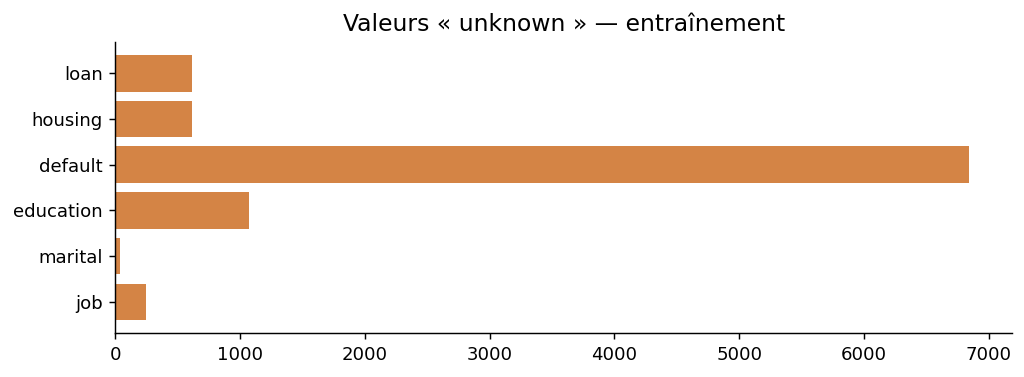

In [5]:
# 3.2 Ne pas confondre NaN, unknown et code sentinelle.
display(pd.DataFrame({'NaN': train_df.isna().sum(),
                      'unknown': (train_df == 'unknown').sum()}))
print('Doublons exacts entraînement :', train_df.duplicated().sum())
print('pdays=999 entraînement :', (train_df.pdays == 999).sum())
figure('unknown.png')


Les valeurs extrêmes ne sont pas supprimées automatiquement : elles peuvent être légitimes.


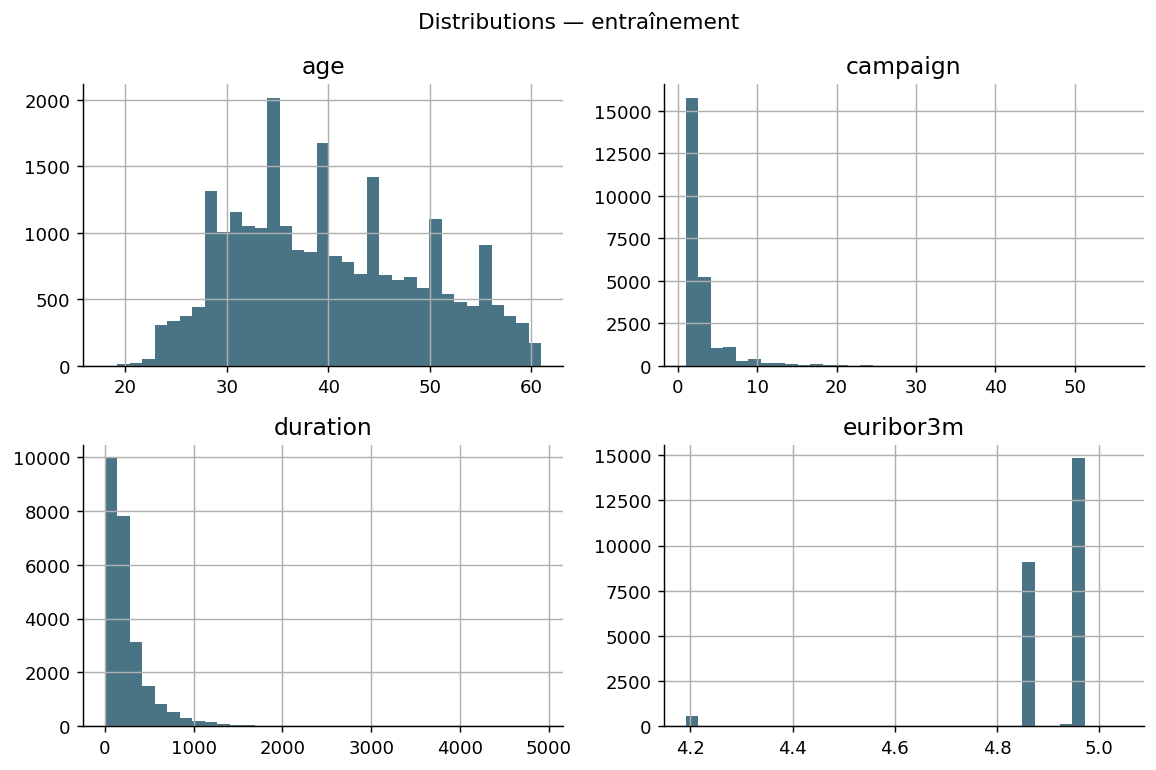

In [6]:
# 3.3 Chaque figure répond à une question : asymétrie, extrêmes, échelle.
figure('distributions.png')
print('Les valeurs extrêmes ne sont pas supprimées automatiquement : elles peuvent être légitimes.')


In [7]:
# 3.3 bis : cas exclusivement tabulaire. Pas de texte libre, image ou audio.
print('Aucune modalité non tabulaire à vectoriser ; pas de justification pour NLP/RAG.')


Aucune modalité non tabulaire à vectoriser ; pas de justification pour NLP/RAG.


Prévalence entraînement : 4.81%
Toujours non : accuracy=95.19%, rappel des souscriptions=0 %


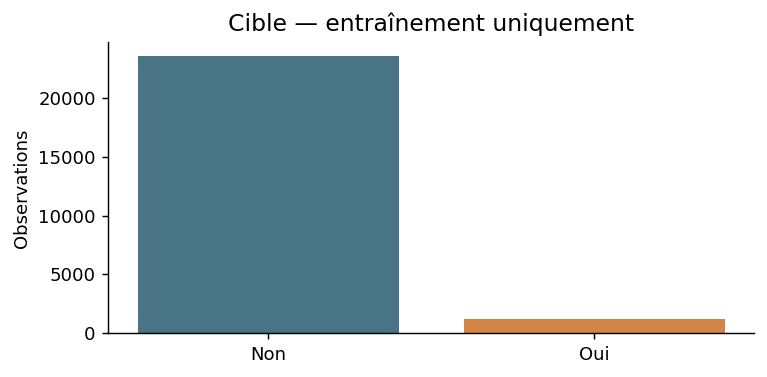

In [8]:
# 3.4 Pourquoi l'accuracy seule est trompeuse.
figure('target.png')
rate = (train_df.y == 'yes').mean()
print(f'Prévalence entraînement : {rate:.2%}')
print(f'Toujours non : accuracy={1-rate:.2%}, rappel des souscriptions=0 %')


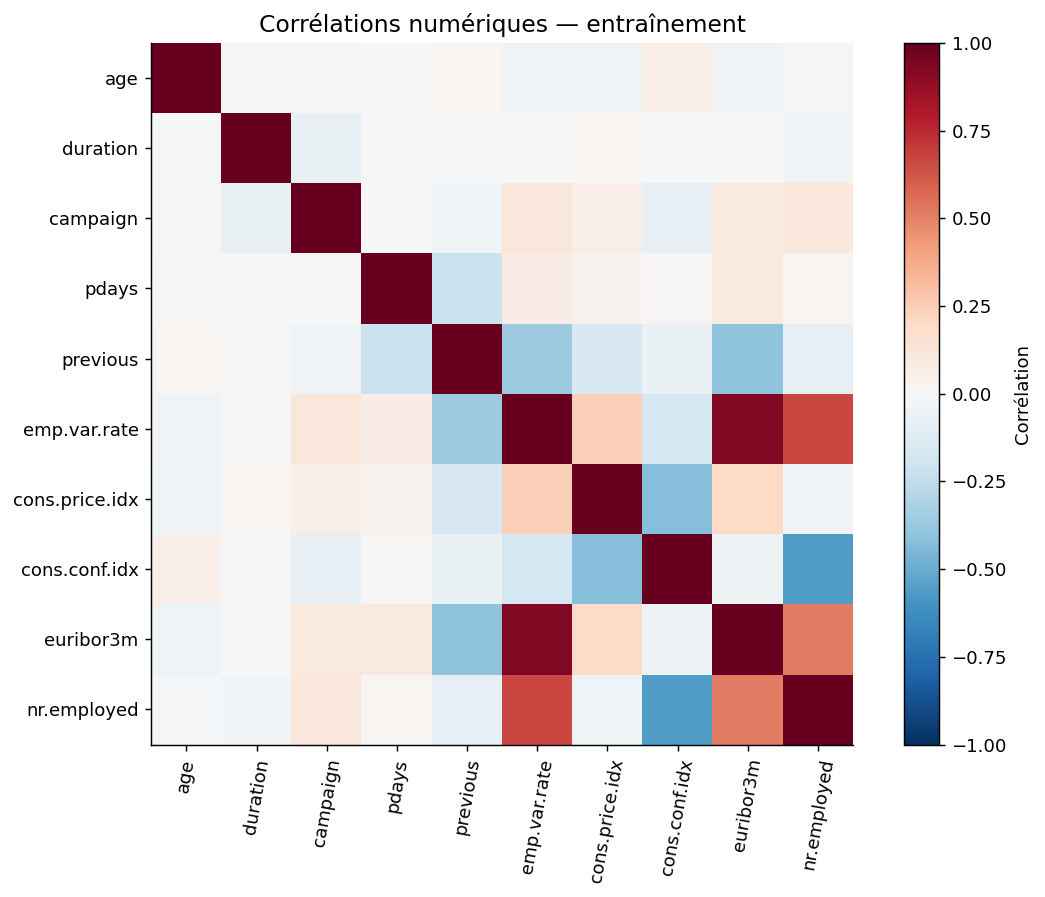

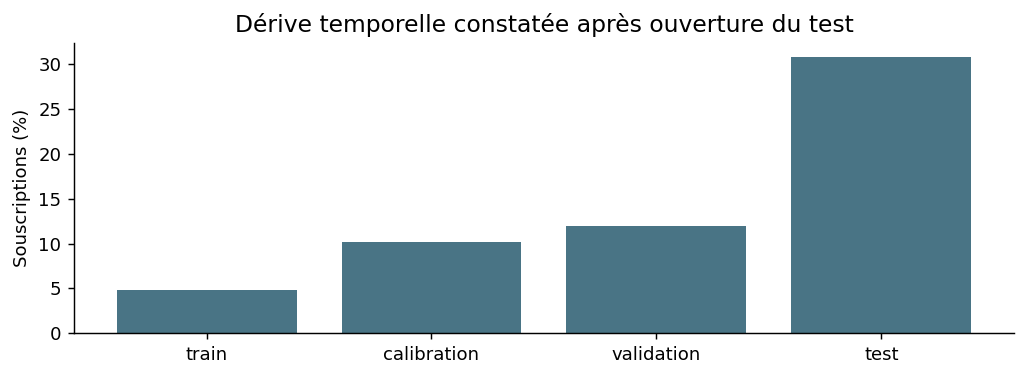

In [9]:
# 3.5 Les variables économiques peuvent être redondantes.
figure('correlations.png')
# Constat final, présenté explicitement après l'évaluation déjà réalisée.
figure('time_shift.png')
